# Naive Bayes Classification in Python

Dataset from Kaggle : **"Netflix Movies and TV Shows"** by *Shivam Bansal*  
Source: https://www.kaggle.com/datasets/shivamb/netflix-shows (requires login)

---

### Essential Libraries

Let us begin by importing the essential Python Libraries.

> NumPy : Library for Numeric Computations in Python  
> Pandas : Library for Data Acquisition and Preparation  
> Matplotlib : Low-level library for Data Visualization  
> Seaborn : Higher-level library for Data Visualization  

In [56]:
# Basic Libraries
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt # we only need pyplot
sb.set() # set the default Seaborn style for graphics

In [57]:
# Print library package version
print("numpy version = "+np.__version__)
print("pandas version = "+pd.__version__)
print("seaborn version = "+sb.__version__)

numpy version = 2.3.5
pandas version = 2.3.3
seaborn version = 0.13.2


---

### Import the Dataset

The dataset is in CSV format; hence we use the `read_csv` function from Pandas.  
Immediately after importing, take a quick look at the data using the `head` function.

In [58]:
netflixdata = pd.read_csv('netflix_titles.csv')
netflixdata.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Description of the dataset, as available on Kaggle, is as follows.

> **show_id** : Unique ID for each title  
> **type** : Whether the title is a Movie or a TV Show  
> **title** : Name of the title  
> **director** : Director(s) of the title  
> **cast** : Main actors in the title  
> **country** : Country or countries where the title was produced  
> **date_added** : Date the title was added to Netflix  
> **release_year** : Year the title was originally released  
> **rating** : Age rating of the title (e.g. TV-MA, PG-13)  
> **duration** : Minutes for movies, number of seasons for TV shows  
> **listed_in** : Genres of the title, separated by commas  
> **description** : Short summary of the title  

---

Check the vital statistics of the dataset using the `type` and `shape` attributes.

In [59]:
print("Data type : ", type(netflixdata))
print("Data dims : ", netflixdata.shape)

Data type :  <class 'pandas.core.frame.DataFrame'>
Data dims :  (8807, 12)


Check the variables (and their types) in the dataset using the `dtypes` attribute.

In [60]:
print(netflixdata.dtypes)

show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object


---

## Clean the Dataset

Before setting up the problem, check the dataset for missing values, duplicates and invalid entries.

In [61]:
# Information about the Variables
netflixdata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [62]:
# Missing values in each Variable
print(netflixdata.isnull().sum())

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [63]:
# Duplicate rows and duplicate descriptions
print("Duplicate rows :", netflixdata.duplicated().sum())
print("Duplicate descriptions :", netflixdata["description"].duplicated().sum())

Duplicate rows : 0
Duplicate descriptions : 32


#### Ratings in the Dataset

Some entries in **rating** are not valid age ratings -- *NR* and *UR* (not rated), and a few durations such as *74 min* entered in the wrong column.

Number of Ratings : 17
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


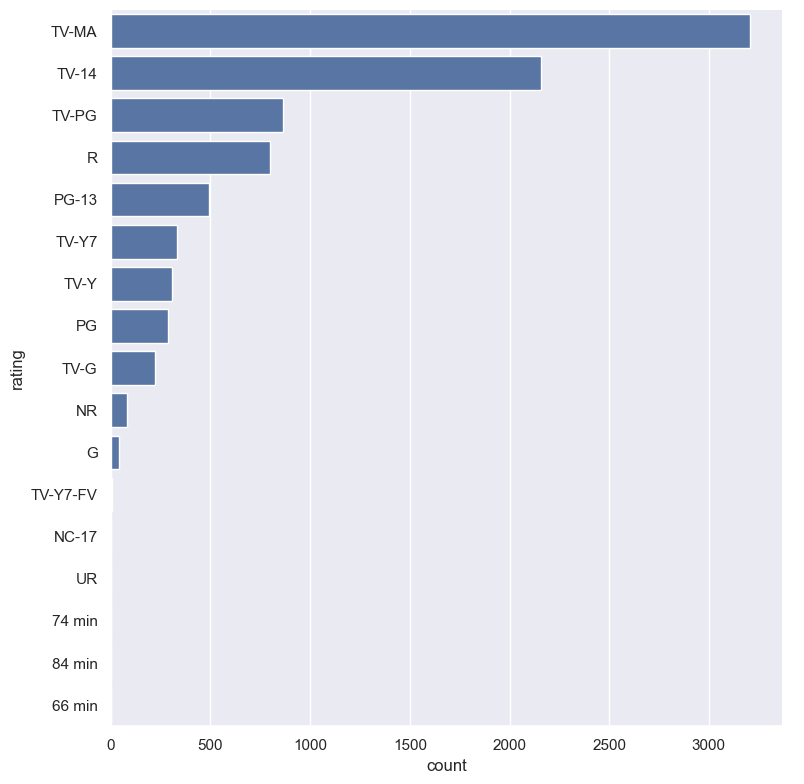

In [64]:
# Ratings in the Dataset
print("Number of Ratings :", len(netflixdata["rating"].dropna().unique()))

# Titles of each Rating
print(netflixdata["rating"].value_counts(dropna = False))
sb.catplot(y = "rating", data = netflixdata, kind = "count",
           order = netflixdata["rating"].value_counts().index, height = 8)

#### Remove Unusable Titles

Keep only titles with a valid age rating, a description and a genre, and remove repeated descriptions.

In [65]:
# Valid Age Ratings
valid_ratings = ["TV-Y", "TV-Y7", "TV-Y7-FV", "TV-G", "G", "PG", "TV-PG",
                 "PG-13", "TV-14", "R", "TV-MA", "NC-17"]

# Keep only the usable Titles
netflixclean = netflixdata[netflixdata["rating"].isin(valid_ratings)]
netflixclean = netflixclean.dropna(subset = ["description", "listed_in"])
netflixclean = netflixclean.drop_duplicates(subset = "description")

# Check the sample sizes
print("Before Cleaning :", netflixdata.shape)
print("After Cleaning  :", netflixclean.shape)

Before Cleaning : (8807, 12)
After Cleaning  : (8686, 12)


---

## Set up the Classification Problem

We will set up a Classification Problem as follows.   

Response Variable : **Adult** (whether the title is rated 18+)     
Predictor Features : **description** and **listed_in** (genre)    

A title is **18+** if its rating is *R*, *TV-MA* or *NC-17*, and **Not 18+** otherwise.

adult
Not 18+    4682
18+        4004
Name: count, dtype: int64


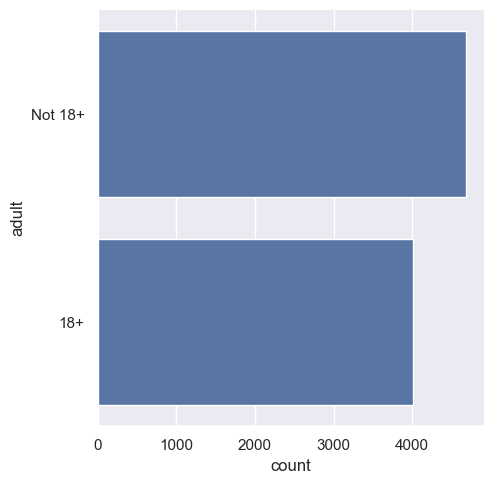

In [66]:
# Create the Response Variable
netflixclean["adult"] = netflixclean["rating"].isin(["R", "TV-MA", "NC-17"])
netflixclean["adult"] = netflixclean["adult"].map({True : "18+", False : "Not 18+"})

# Titles in each Class
print(netflixclean["adult"].value_counts())
sb.catplot(y = "adult", data = netflixclean, kind = "count")

#### Combine Description and Genre

Each genre is converted into a single token with a `g_` prefix -- e.g. *International Movies* becomes `g_International_Movies`.  
This keeps a multi-word genre as one feature, and keeps genres separate from the words in the description.

In [67]:
# Convert the Genres of each title into Genre tokens
def genre_tokens(genres):
    tokens = []
    for g in genres.split(", "):
        g = g.replace(" ", "_").replace("'", "").replace("-", "_").replace("&", "and")
        tokens.append("g_" + g)
    return " ".join(tokens)

netflixclean["genre"] = netflixclean["listed_in"].apply(genre_tokens)

# Combine Description and Genre into a single text
netflixclean["text"] = netflixclean["description"] + " " + netflixclean["genre"]

# Check the first title
print(netflixclean["listed_in"].iloc[0])
print(netflixclean["text"].iloc[0])

Documentaries
As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable. g_Documentaries


---

## Explore the Dataset

Perform basic statistical exploration and visualization on the Response and Predictors.

#### Baseline Accuracy

If we always guess the most common class, this is the accuracy we would get. Any model should beat this.

In [68]:
# Proportion of each Class
print(netflixclean["adult"].value_counts(normalize = True))
print()
print("Baseline Accuracy \t:", netflixclean["adult"].value_counts(normalize = True).max())

adult
Not 18+    0.539028
18+        0.460972
Name: proportion, dtype: float64

Baseline Accuracy 	: 0.5390283214367948


#### Length of the Description

In [69]:
# Number of words in each Description
desc_len = pd.DataFrame(netflixclean["description"].str.split().str.len())
desc_len.columns = ["Length"]

# Summary Statistics for Description Length
desc_len.describe()

,Length
count,8686.000000
mean,23.885333
std,2.842595
min,10.000000
25%,22.000000
50%,24.000000
75%,26.000000
max,48.000000


<Axes: >

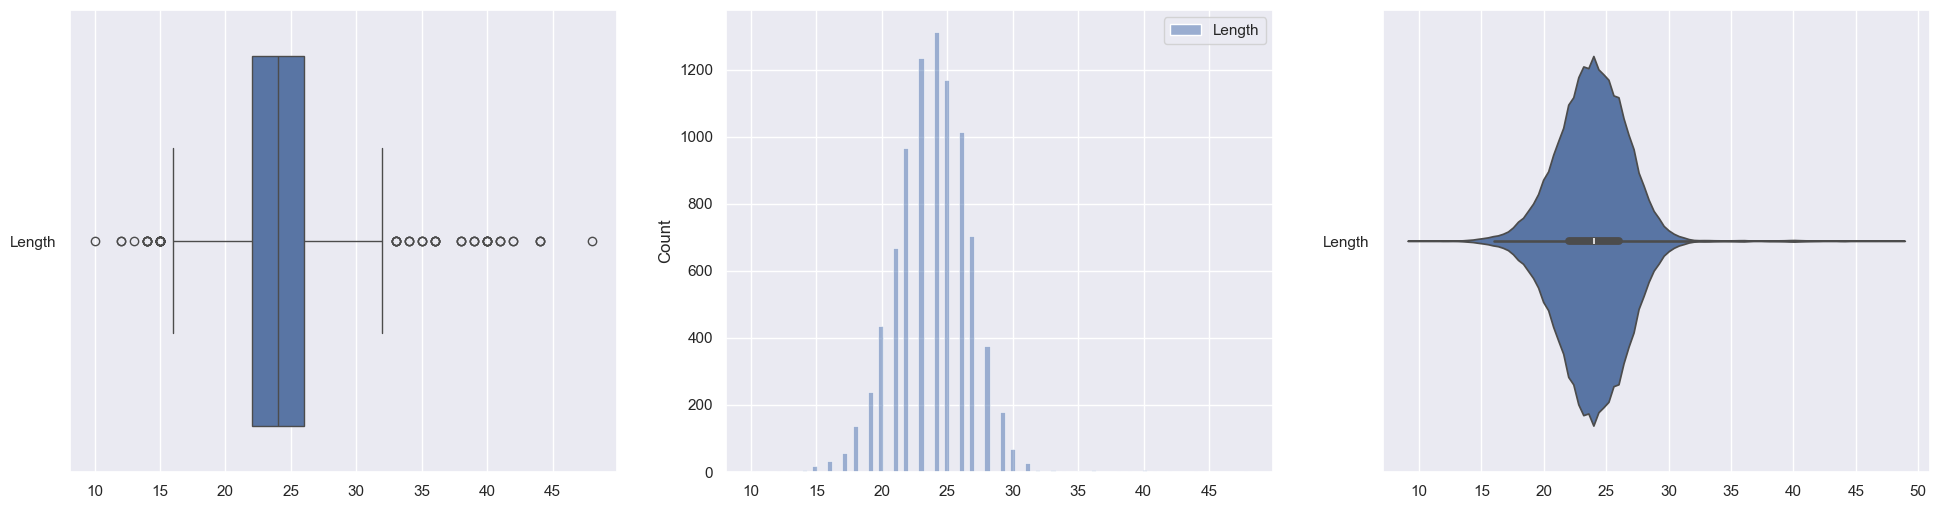

In [70]:
# Plot the distributions of Description Length
f, axes = plt.subplots(1, 3, figsize=(24, 6))
sb.boxplot(data = desc_len, orient = "h", ax = axes[0])
sb.histplot(data = desc_len, ax = axes[1])
sb.violinplot(data = desc_len, orient = "h", ax = axes[2])

<Axes: xlabel='Length', ylabel='adult'>

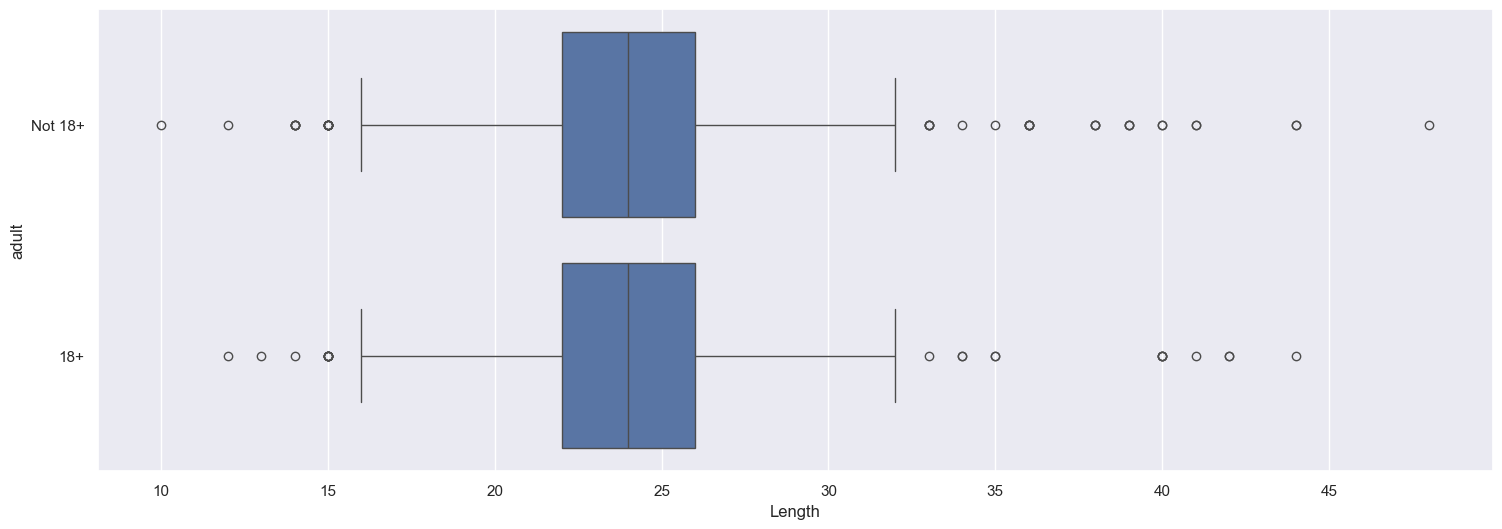

In [71]:
# Create a joint dataframe by concatenating Length and Adult
lenDF = pd.concat([desc_len, netflixclean["adult"]], axis = 1).reindex(desc_len.index)

# Joint Boxplot of Length against Adult
f = plt.figure(figsize=(18, 6))
sb.boxplot(x = "Length", y = "adult", data = lenDF, orient = "h")

#### Most Common Words in each Class

In [72]:
# Import CountVectorizer from sklearn.feature_extraction.text
from sklearn.feature_extraction.text import CountVectorizer

# Top 15 words (ignoring common English words) in each Class
for cls in ["18+", "Not 18+"]:
    words = CountVectorizer(stop_words = "english")
    counts = words.fit_transform(netflixclean[netflixclean["adult"] == cls]["description"])
    top = pd.Series(counts.sum(axis = 0).A1, index = words.get_feature_names_out())
    print(cls, ":", list(top.nlargest(15).index))
    print()

18+ : ['life', 'young', 'new', 'family', 'man', 'woman', 'world', 'love', 'series', 'documentary', 'friends', 'group', 'takes', 'stand', 'murder']

Not 18+ : ['life', 'young', 'new', 'world', 'family', 'love', 'friends', 'man', 'woman', 'series', 'school', 'documentary', 'help', 'father', 'home']



#### Genres against Adult

Share of 18+ titles within each genre (genres with at least 100 titles).

In [73]:
# One row for each Genre of each title
genreDF = netflixclean[["listed_in", "adult"]].copy()
genreDF["listed_in"] = genreDF["listed_in"].str.split(", ")
genreDF = genreDF.explode("listed_in").reset_index(drop = True)

# Count the titles in each Genre and Class
genre_counts = genreDF.groupby(["listed_in", "adult"]).size().unstack(fill_value = 0)
genre_counts = genre_counts[genre_counts.sum(axis = 1) >= 100]

# Share of 18+ titles in each Genre
genre_share = genre_counts["18+"] / genre_counts.sum(axis = 1)
genre_share = genre_share.sort_values()
print(genre_share.round(2))

listed_in
Kids' TV                     0.00
Children & Family Movies     0.00
Korean TV Shows              0.32
Reality TV                   0.33
Romantic Movies              0.34
Anime Series                 0.34
Romantic TV Shows            0.36
Comedies                     0.37
Classic Movies               0.38
Music & Musicals             0.38
Sci-Fi & Fantasy             0.40
Documentaries                0.41
Sports Movies                0.42
British TV Shows             0.43
Docuseries                   0.45
International Movies         0.46
TV Comedies                  0.46
Action & Adventure           0.50
Dramas                       0.50
International TV Shows       0.53
TV Action & Adventure        0.54
TV Dramas                    0.57
Thrillers                    0.69
LGBTQ Movies                 0.72
Independent Movies           0.73
Horror Movies                0.74
Crime TV Shows               0.75
Spanish-Language TV Shows    0.75
Stand-Up Comedy              0.88
dtyp

Text(0.5, 0, 'Share of 18+ titles')

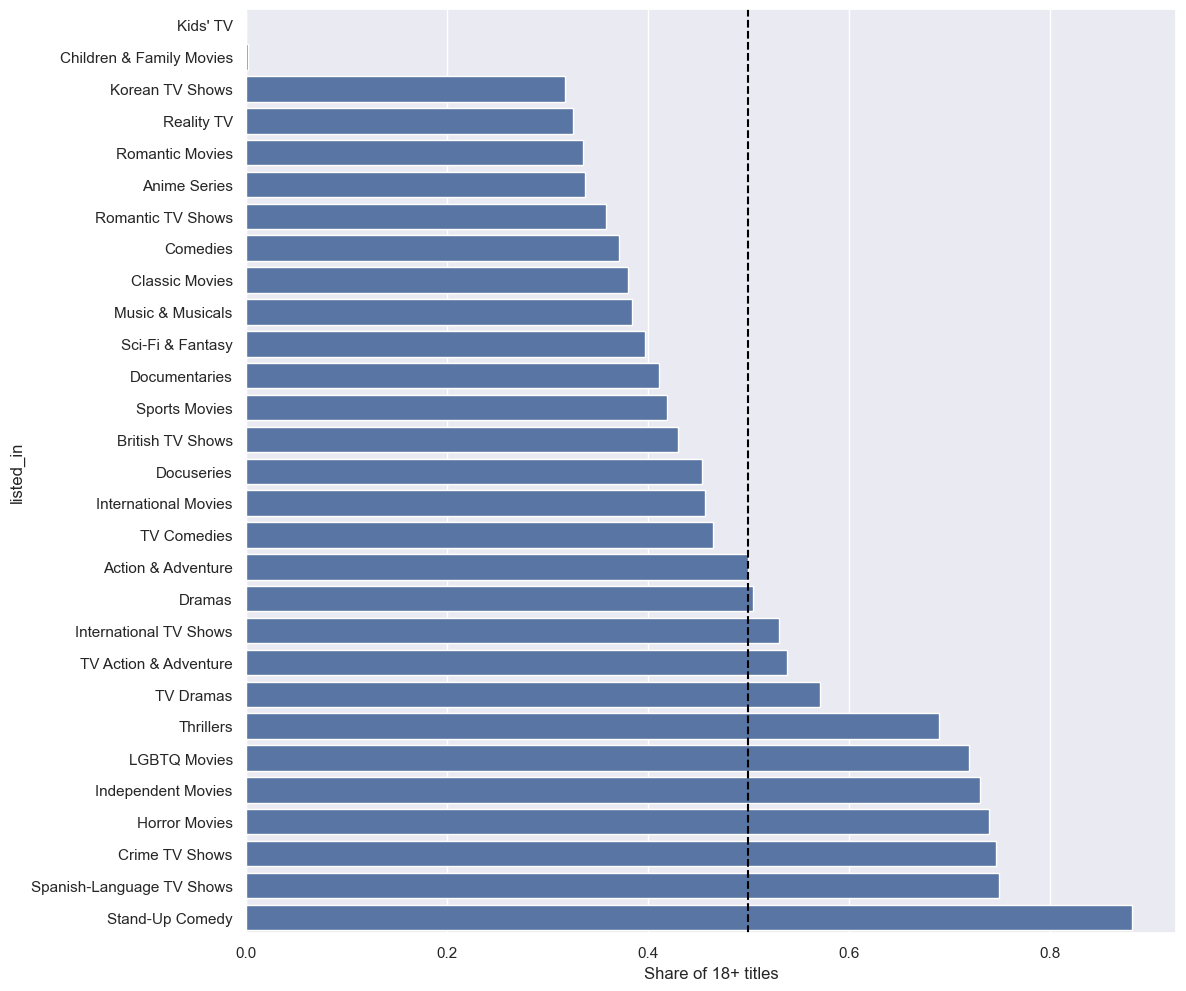

In [74]:
# Plot the Share of 18+ titles in each Genre
f = plt.figure(figsize=(12, 12))
sb.barplot(x = genre_share.values, y = genre_share.index, orient = "h")
plt.axvline(0.5, color = "black", linestyle = "--")
plt.xlabel("Share of 18+ titles")

---

## Naive Bayes Classifier

#### Split into Train and Test

Split the dataset randomly into Train (80%) and Test (20%) sets.  
`stratify` keeps the same proportion of 18+ and Not 18+ titles in both sets.

In [75]:
# Import train_test_split from sklearn
from sklearn.model_selection import train_test_split

# Extract Response and Predictors
y = pd.DataFrame(netflixclean["adult"])   # Response
X = pd.DataFrame(netflixclean["text"])    # Predictor

# Split the Dataset into Train and Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2,
                                                    stratify = y, random_state = 42)

# Check the sample sizes
print("Train Set :", y_train.shape, X_train.shape)
print("Test Set  :", y_test.shape, X_test.shape)

Train Set : (6948, 1) (6948, 1)
Test Set  : (1738, 1) (1738, 1)


#### Convert Text to Word Counts

A model can only work with numbers, so each title's text is converted into word counts using `CountVectorizer`.  
The vocabulary is learnt from the **Train Set only**, then the same vocabulary is used on the Test Set.

In [76]:
# Create a CountVectorizer object (keep every word, including genre tokens)
vectorizer = CountVectorizer(token_pattern = r"(?u)\b\w+\b")

# Learn the vocabulary from Train, and count words in Train and Test
X_train_counts = vectorizer.fit_transform(X_train["text"])
X_test_counts = vectorizer.transform(X_test["text"])

# Check the sizes (titles, words in vocabulary)
print("Train Counts :", X_train_counts.shape)
print("Test Counts  :", X_test_counts.shape)

Train Counts : (6948, 17163)
Test Counts  : (1738, 17163)


#### Choose the Smoothing Parameter

`alpha` is the smoothing in Naive Bayes -- it adds a small count to every word so no word has a probability of zero.  
We pick the best `alpha` using 5-fold Cross-Validation on the Train Set.

In [77]:
# Import MultinomialNB and cross_val_score from sklearn
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import cross_val_score

# Try different values of alpha
for alpha in [0.1, 0.5, 1, 2]:
    nbmodel = MultinomialNB(alpha = alpha)
    scores = cross_val_score(nbmodel, X_train_counts, y_train["adult"], cv = 5, scoring = "f1_macro")
    print("alpha =", alpha, "\tMacro-F1 :", round(scores.mean(), 3))

alpha = 0.1 	Macro-F1 : 0.679
alpha = 0.5 	Macro-F1 : 0.691
alpha = 1 	Macro-F1 : 0.693
alpha = 2 	Macro-F1 : 0.697


#### Naive Bayes in Scikit-Learn

Train the Naive Bayes model `nbmodel` using the Train Set with the best `alpha`.

In [78]:
# Create a Naive Bayes object with the best alpha
nbmodel = MultinomialNB(alpha = 2)

# Train the Naive Bayes model
nbmodel.fit(X_train_counts, y_train["adult"])

,alpha,2
,force_alpha,True
,fit_prior,True
,class_prior,None


#### Goodness of Fit of the Model

Check how good the predictions are on the Train Set.    
Metrics : Classification Accuracy and Confusion Matrix.

Classification Accuracy 	: 0.885146804835924


Text(67.25, 0.5, 'Actual')

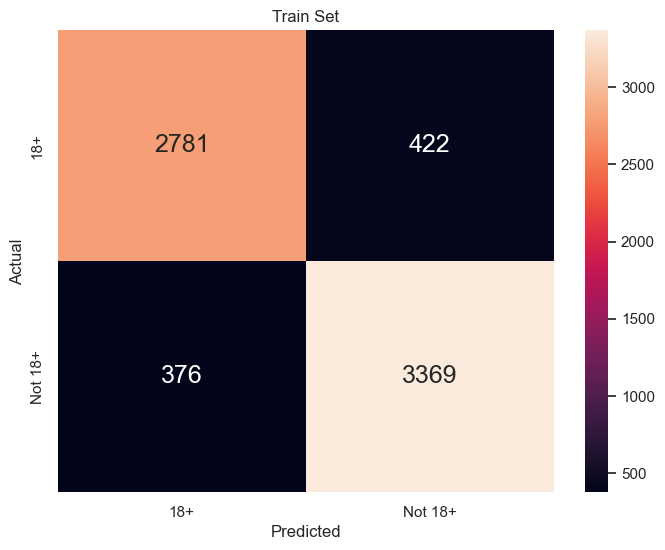

In [79]:
# Import confusion_matrix from sklearn
from sklearn.metrics import confusion_matrix

# Predict Adult corresponding to Text Train
y_train_pred = nbmodel.predict(X_train_counts)

# Print the Classification Accuracy
print("Classification Accuracy \t:", nbmodel.score(X_train_counts, y_train["adult"]))

# Plot the two-way Confusion Matrix
f = plt.figure(figsize=(8, 6))
sb.heatmap(confusion_matrix(y_train, y_train_pred, labels = ["18+", "Not 18+"]),
           annot = True, fmt=".0f", annot_kws={"size": 18},
           xticklabels = ["18+", "Not 18+"], yticklabels = ["18+", "Not 18+"])
plt.title("Train Set")
plt.xlabel("Predicted")
plt.ylabel("Actual")

Classification Accuracy 	: 0.7174913693901036


Text(67.25, 0.5, 'Actual')

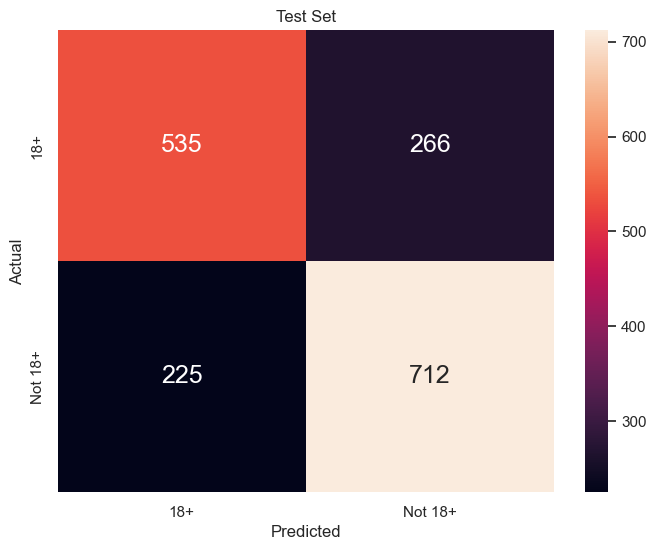

In [80]:
# Predict Adult corresponding to Text Test
y_test_pred = nbmodel.predict(X_test_counts)

# Print the Classification Accuracy
print("Classification Accuracy \t:", nbmodel.score(X_test_counts, y_test["adult"]))

# Plot the two-way Confusion Matrix
f = plt.figure(figsize=(8, 6))
sb.heatmap(confusion_matrix(y_test, y_test_pred, labels = ["18+", "Not 18+"]),
           annot = True, fmt=".0f", annot_kws={"size": 18},
           xticklabels = ["18+", "Not 18+"], yticklabels = ["18+", "Not 18+"])
plt.title("Test Set")
plt.xlabel("Predicted")
plt.ylabel("Actual")

Look at Precision, Recall and F1-score for each class on the Test Set.

In [81]:
# Import classification_report from sklearn
from sklearn.metrics import classification_report

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

         18+       0.70      0.67      0.69       801
     Not 18+       0.73      0.76      0.74       937

    accuracy                           0.72      1738
   macro avg       0.72      0.71      0.71      1738
weighted avg       0.72      0.72      0.72      1738



---

## Does Genre Help?

Train the same model on three different Predictors -- **description only**, **genre only**, and **description + genre** -- using the same Train and Test titles.

In [82]:
# Import f1_score from sklearn
from sklearn.metrics import f1_score

# Same Train and Test titles, different Predictors
predictors = ["description", "genre", "text"]

for var in predictors:
    vec = CountVectorizer(token_pattern = r"(?u)\b\w+\b")
    train_counts = vec.fit_transform(netflixclean.loc[X_train.index, var])
    test_counts = vec.transform(netflixclean.loc[X_test.index, var])

    model = MultinomialNB(alpha = 2)
    model.fit(train_counts, y_train["adult"])
    pred = model.predict(test_counts)

    print("Predictor :", var)
    print("Classification Accuracy \t:", round(model.score(test_counts, y_test["adult"]), 3))
    print("Macro-F1 \t\t\t:", round(f1_score(y_test["adult"], pred, average = "macro"), 3))
    print()

Predictor : description
Classification Accuracy 	: 0.682
Macro-F1 			: 0.677

Predictor : genre
Classification Accuracy 	: 0.687
Macro-F1 			: 0.677

Predictor : text
Classification Accuracy 	: 0.717
Macro-F1 			: 0.715



---

## What the Model Learnt

Compare the probability of each word in the two classes.  
Words with a much higher probability in one class push the prediction towards that class.

In [83]:
# Words in the vocabulary
words = vectorizer.get_feature_names_out()

# Difference in log-probability : positive means more typical of 18+
adult_idx = list(nbmodel.classes_).index("18+")
other_idx = 1 - adult_idx
diff = pd.Series(nbmodel.feature_log_prob_[adult_idx] - nbmodel.feature_log_prob_[other_idx], index = words)

# Split into Genre tokens and Description words
genre_diff = diff[diff.index.str.startswith("g_")]
word_diff = diff[~diff.index.str.startswith("g_")]

print("Genres pointing to 18+ \t\t:", list(genre_diff.nlargest(10).index))
print("Genres pointing to Not 18+ \t:", list(genre_diff.nsmallest(10).index))
print()
print("Words pointing to 18+ \t\t:", list(word_diff.nlargest(10).index))
print("Words pointing to Not 18+ \t:", list(word_diff.nsmallest(10).index))

Genres pointing to 18+ 		: ['g_stand_up_comedy', 'g_spanish_language_tv_shows', 'g_crime_tv_shows', 'g_horror_movies', 'g_tv_horror', 'g_independent_movies', 'g_lgbtq_movies', 'g_thrillers', 'g_tv_thrillers', 'g_stand_up_comedy_and_talk_shows']
Genres pointing to Not 18+ 	: ['g_kids_tv', 'g_children_and_family_movies', 'g_faith_and_spirituality', 'g_science_and_nature_tv', 'g_anime_features', 'g_tv_sci_fi_and_fantasy', 'g_movies', 'g_korean_tv_shows', 'g_teen_tv_shows', 'g_reality_tv']

Words pointing to 18+ 		: ['comedians', 'horror', 'comedian', 'sexuality', 'drugs', 'australian', 'boston', 'rapper', 'spirals', 'addict']
Words pointing to Not 18+ 	: ['bheem', 'fairy', 'animated', 'magical', 'rangers', 'curious', 'barbie', 'ninja', 'pets', 'rainbow']
